In [1]:
import numpy as np
import pandas as pd
from sklearn.svm import SVC
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.DataFrame({
    'x': np.random.normal(size=50),
    'y': np.random.normal(size=50),
})

df['flag'] = (df['x'] * 3 + df['y'] * 2 - 4 > 0).astype(int)
df

,x,y,flag
0,1.736963,0.426818,1
1,0.947686,0.726558,1
2,0.505923,0.865520,0
3,0.938602,0.784991,1
4,1.438469,0.497359,1
5,0.514441,0.520455,0
6,0.291929,0.433665,0
7,1.101136,0.348001,0
8,0.497808,0.819937,0
9,1.288203,0.670830,1


In [17]:
model = SVC(kernel='linear', C=1000)

X = df.drop(columns=['flag'])
y = df['flag']

model.fit(X, y)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


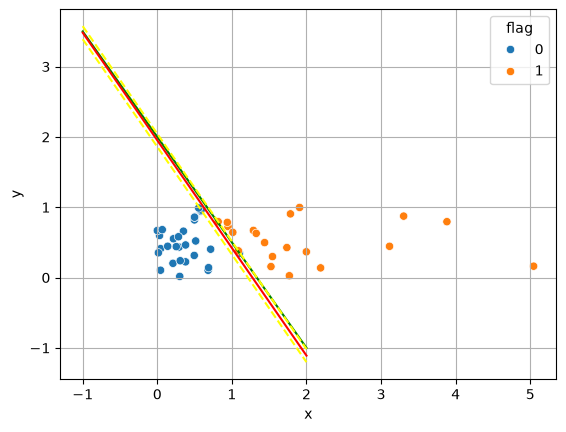

In [18]:
w = model.coef_[0]
b = model.intercept_[0]

xx = np.linspace(-1, 2, 100)
true_line = -1.5 * xx + 2

margin = -(w[0] * xx + b) / w[1]
margin_plus = (1 - w[0] * xx - b) / w[1]
margin_minus = (-1 - w[0] * xx - b) / w[1]

sns.scatterplot(
    data=df,
    x='x',
    y='y',
    hue='flag',
)
plt.plot(xx, true_line, c='green')
plt.plot(xx, margin, color='red')
plt.plot(xx, margin_plus, color='yellow', linestyle='--')
plt.plot(xx, margin_minus, color='yellow', linestyle='--')
sv = model.support_vectors_
# plt.scatter(sv[:, 0], sv[:, 1],
#            s=250, facecolors='none', edgecolors='red', linewidths=2,
#            label=f'support vectors ({len(sv)})')

plt.grid()

In [5]:
df2 = pd.read_csv('multi-class.csv')
df2.head()

,x,y,flag
0,0.000000,-0.559158,1
1,-0.994996,0.559158,2
2,0.994996,-1.304703,3
3,-1.492494,-0.186386,4
4,0.497498,0.931930,5


<Axes: xlabel='x', ylabel='y'>

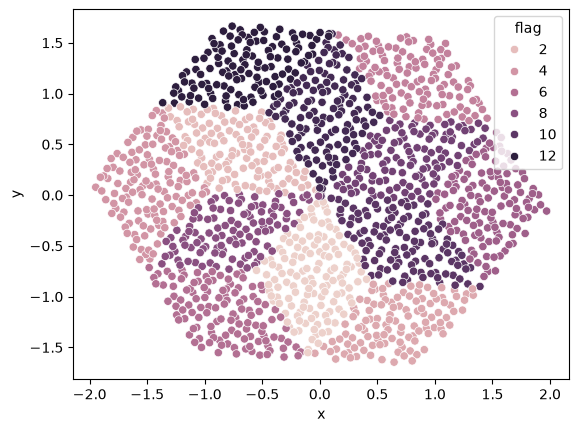

In [6]:
sns.scatterplot(df2, x='x', y='y', hue='flag')

In [15]:
X = df2.drop(columns=['flag'])
y = df2['flag']

model2 = SVC(kernel='linear').fit(X, y)

/Users/nagiev/famcs-archive/.venv/lib/python3.11/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(
/Users/nagiev/famcs-archive/.venv/lib/python3.11/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'colors' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


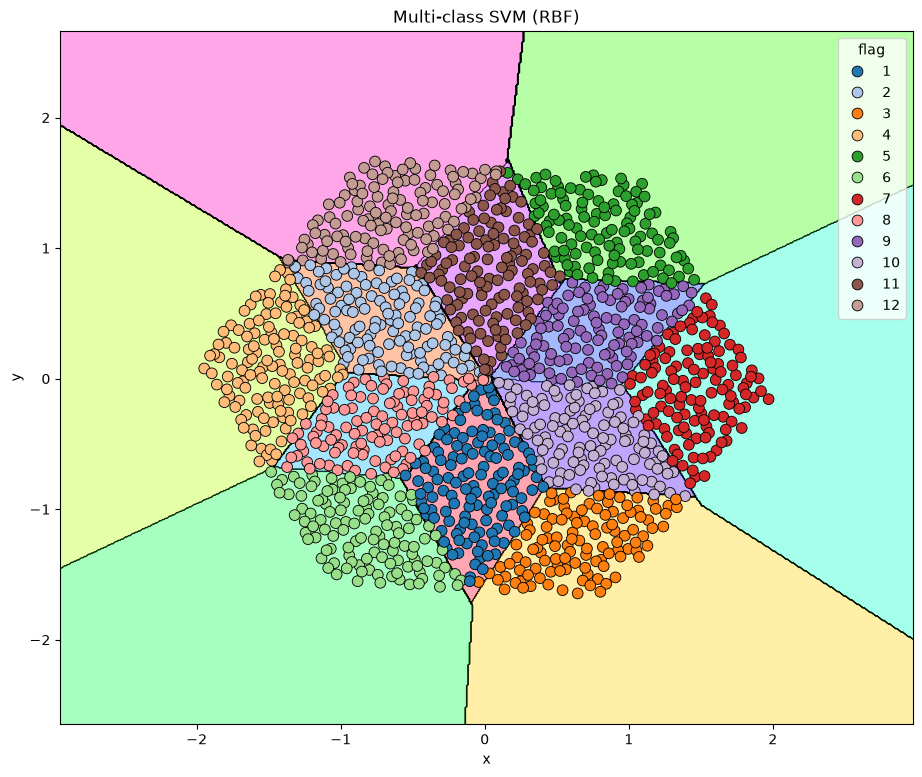

In [16]:
from sklearn.inspection import DecisionBoundaryDisplay

fig, ax = plt.subplots(figsize=(11, 9))
DecisionBoundaryDisplay.from_estimator(
    model2, X, response_method="predict",
    cmap="tab20", alpha=0.35, grid_resolution=600, ax=ax,
)
DecisionBoundaryDisplay.from_estimator(
    model2, X, response_method="predict", plot_method="contour",
    colors="k", linewidths=0.5, grid_resolution=600, ax=ax,
)
sns.scatterplot(data=df2, x='x', y='y', hue='flag',
                palette='tab20', s=60, edgecolor='k', ax=ax)
ax.set_title("Multi-class SVM (RBF)")
plt.show()

In [9]:
model3 = SVC(kernel='sigmoid')
model3.fit(X, y)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'sigmoid'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


/Users/nagiev/famcs-archive/.venv/lib/python3.11/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(
/Users/nagiev/famcs-archive/.venv/lib/python3.11/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'colors' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


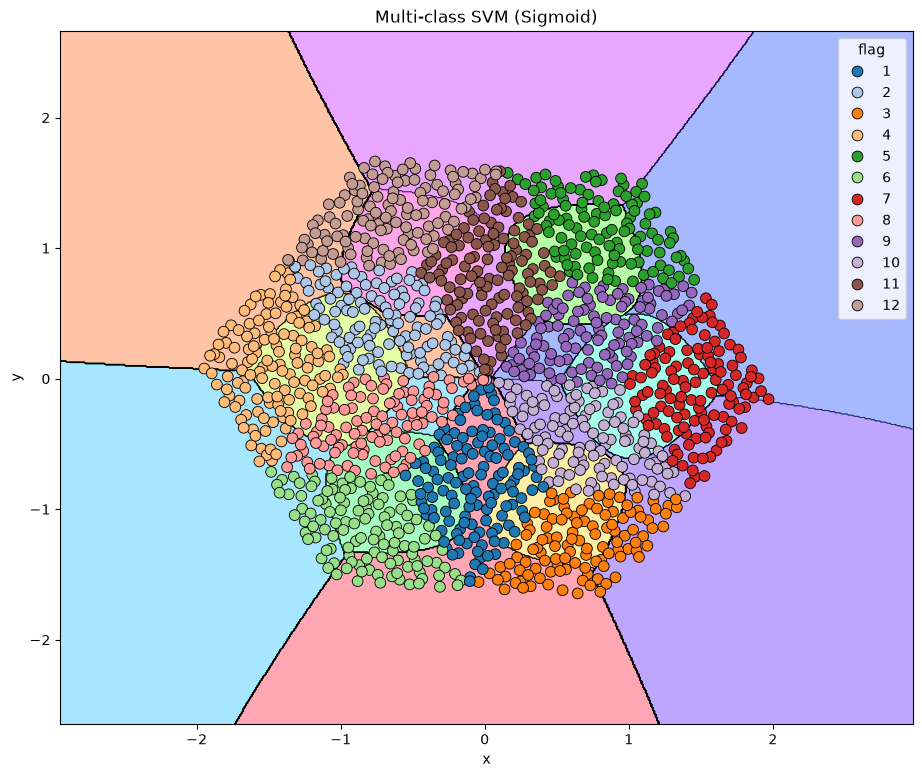

In [10]:
fig, ax = plt.subplots(figsize=(11, 9))
DecisionBoundaryDisplay.from_estimator(
    model3, X, response_method="predict",
    cmap="tab20", alpha=0.35, grid_resolution=600, ax=ax,
)
DecisionBoundaryDisplay.from_estimator(
    model3, X, response_method="predict", plot_method="contour",
    colors="k", linewidths=0.5, grid_resolution=600, ax=ax,
)
sns.scatterplot(data=df2, x='x', y='y', hue='flag',
                palette='tab20', s=60, edgecolor='k', ax=ax)
ax.set_title("Multi-class SVM (Sigmoid)")
plt.show()